# CLIP zero-shot on Country211: Austria vs Australia

Question: **where and why does CLIP confuse Austria and Australia?** Accuracy cannot answer this, so the analysis looks at the structure of the image embedding space:

1. Map all images in 2D and mark the errors.
2. Cluster the images. For each cluster measure: error rate, density, spread, scene content, and whether the error is image-side or text-side.
3. Look at what is inside the worst cluster: split it into sub-clusters and compare them.

Scene types are not labeled in Country211, so scenes are estimated with CLIP text probes. Turn Internet on.

## Setup


In [23]:
import tarfile
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import transformers
from transformers import CLIPModel, CLIPProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ["AT", "AU"]                     # Austria, Australia
EXTS = {".jpg", ".jpeg", ".png", ".webp"}
MODEL_ID = "openai/clip-vit-base-patch32"


In [24]:
def find_root():
    """Find the Country211 folder whose train/valid/test contain AT and AU subfolders."""
    for base in (Path("/kaggle/working"), Path("/kaggle/input")):
        for t in base.glob("**/test"):
            if (t / "AT").is_dir() and (t / "AU").is_dir():
                return t.parent
    return None

root = find_root()
if root is None:  # extract the archive once
    tgz_list = sorted(Path("/kaggle/input").glob("**/country211.tgz"))
    if not tgz_list:
        raise RuntimeError("No extracted Country211 and no country211.tgz under /kaggle/input - attach the dataset first.")
    out = Path("/kaggle/working/country211"); out.mkdir(exist_ok=True)
    with tarfile.open(tgz_list[0]) as a:
        a.extractall(out, filter="data")
    root = find_root()


In [25]:
proc = CLIPProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
print(f"transformers {transformers.__version__} | torch {torch.__version__} | device: {DEVICE}")
print("Data:", root, "| Device:", DEVICE)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

transformers 5.20.2 | torch 2.11.0+cpu | device: cpu
Data: /kaggle/working/country211/country211 | Device: cpu


## Embeddings and zero-shot scores


In [26]:
@torch.inference_mode()
def embed_text(texts):
    t = proc(text=texts, return_tensors="pt", padding=True).to(DEVICE)
    text_outputs = model.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"])
    text_features = model.text_projection(text_outputs.pooler_output)
    return F.normalize(text_features, dim=-1).cpu().numpy()

@torch.inference_mode()
def embed_images(paths, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        ims = []
        for p in paths[i:i + bs]:
            with Image.open(p) as im:
                ims.append(im.convert("RGB"))
        try:
            px = proc(images=ims, return_tensors="pt")["pixel_values"].to(DEVICE)
        finally:
            for im in ims:
                im.close()
        vision_outputs = model.vision_model(pixel_values=px)
        image_features = model.visual_projection(vision_outputs.pooler_output)
        out.append(F.normalize(image_features, dim=-1).cpu().numpy())
    return np.concatenate(out)


In [27]:
# All 600 AT/AU images (Country211: 150/50/100 per country; nothing is trained, so every split is unseen).
df = pd.DataFrame(
    [(str(p), c, s) for s in ("train", "valid", "test") for c in CLASSES
     for p in sorted((root / s / c).iterdir()) if p.suffix.lower() in EXTS],
    columns=["path", "country", "split"])
print(df.groupby(["split", "country"]).size())   # sanity: 150/50/100 per country
y = (df.country == "AU").to_numpy().astype(int)


split  country
test   AT         100
       AU         100
train  AT         150
       AU         150
valid  AT          50
       AU          50
dtype: int64


In [28]:
X = embed_images(df.path.tolist())
print(X.shape)


(600, 512)


In [29]:
# Zero-shot: signed margin (logit of true class minus other class; negative = error)
scale = model.logit_scale.exp().item()
PROMPTS = {
    "English names": ["Austria", "Australia"],
    "German names": ["Österreich", "Australien"],
    "Austria / Australien": ["Austria", "Australien"],
    "Österreich / Australia": ["Österreich", "Australia"],
    "photo template": ["a photo taken in Austria", "a photo taken in Australia"],
}
T = {name: embed_text(v) for name, v in PROMPTS.items()}   # embed each prompt pair once
lg = scale * X @ T["photo template"].T
df["au_score"] = lg[:, 1] - lg[:, 0]
df["margin"] = df["au_score"] * (2 * y - 1)
df["n_wrong"] = sum(((X @ etxt.T).argmax(1) != y).astype(int) for etxt in T.values())
print("zero-shot error rate (photo template):", (df.margin < 0).mean().round(3))


zero-shot error rate (photo template): 0.17


## Image-side check and scene probes


In [30]:
# Image-side check: does a 10-nearest-neighbour vote (leave-one-out) get it right?
# (ties at 5-5 vote AU)
S = X @ X.T
np.fill_diagonal(S, -np.inf)
nn = np.argsort(-S, axis=1)[:, :10]
df["knn_err"] = ((y[nn].mean(1) >= 0.5).astype(int) != y)
df["dens"] = np.take_along_axis(S, nn, axis=1).mean(1)   # local density: mean similarity to 10 nearest neighbours


In [31]:
# Scene estimate (CLIP text probes; the dataset has no scene labels, and these probes are unreliable)
SCENES = ["city street", "building", "church", "mountains", "snow", "beach", "desert",
          "forest", "countryside fields", "river or lake", "sign with text", "people", "animal", "food"]
sc = scale * X @ embed_text([f"a photo of {s}" for s in SCENES]).T
df["scene"] = np.array(SCENES)[sc.argmax(1)]


## Clusters (k by silhouette) and 2D map


In [32]:
# Cluster the image embeddings; pick k by silhouette.
def best_kmeans(Xs, ks):
    best = None
    for k in ks:
        km = KMeans(k, n_init=10, random_state=0).fit(Xs)
        s = silhouette_score(Xs, km.labels_)
        if best is None or s > best[1]:
            best = (km, s)
    return best

km, sil = best_kmeans(X, range(2, 11))
df["cl"] = km.labels_
print(f"k = {km.n_clusters}, silhouette = {sil:.2f}")


k = 9, silhouette = 0.05


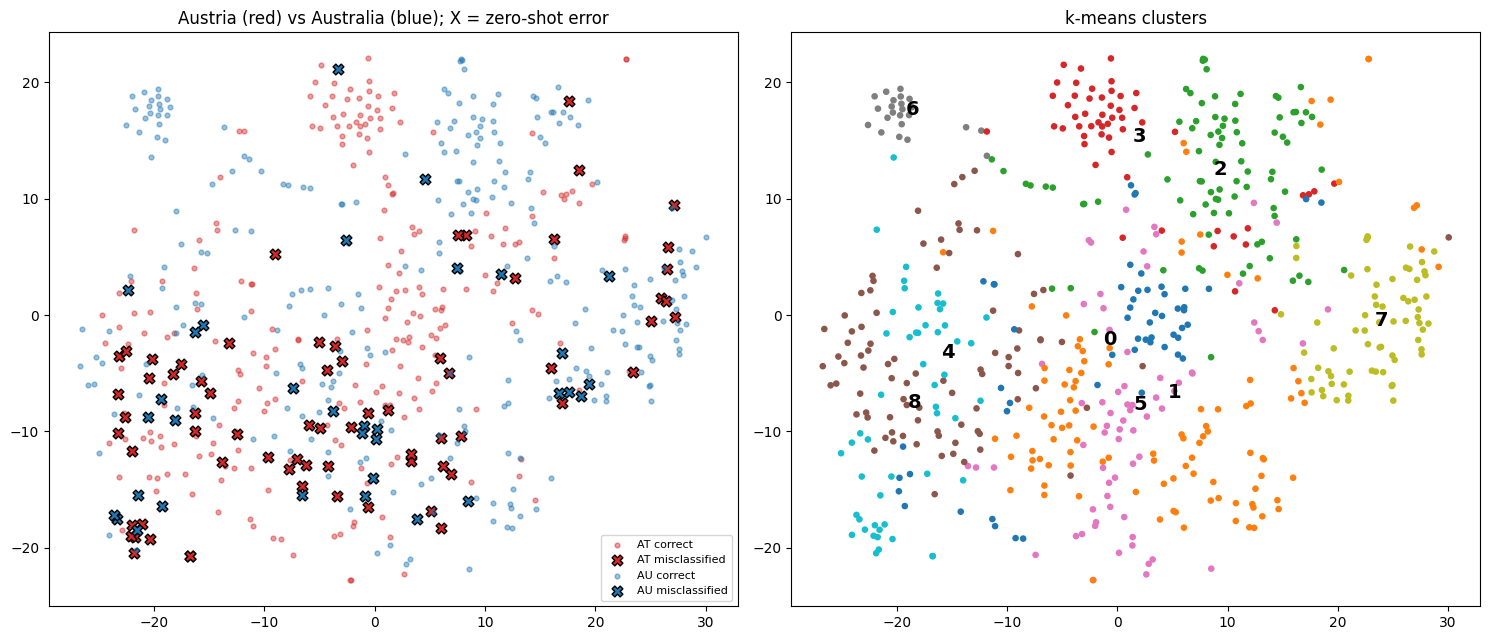

In [33]:
# Figure 1: 2D map of the images. Left: country + errors. Right: clusters.
Z = TSNE(2, metric="cosine", perplexity=30, init="pca", random_state=0).fit_transform(X)
err = (df.margin < 0).to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
for c, col in zip(CLASSES, ("tab:red", "tab:blue")):
    m = (df.country == c).to_numpy()
    ax[0].scatter(Z[m & ~err, 0], Z[m & ~err, 1], s=12, c=col, alpha=.45, label=f"{c} correct")
    ax[0].scatter(Z[m & err, 0], Z[m & err, 1], s=60, c=col, marker="X", edgecolor="k", label=f"{c} misclassified")
ax[0].legend(fontsize=8); ax[0].set_title("Austria (red) vs Australia (blue); X = zero-shot error")
ax[1].scatter(Z[:, 0], Z[:, 1], c=df.cl, cmap="tab10", s=14)
for c in range(km.n_clusters):
    ax[1].annotate(str(c), Z[df.cl == c].mean(0), fontsize=14, weight="bold")
ax[1].set_title("k-means clusters")
plt.tight_layout(); plt.show()


## Per-cluster summary and montage


In [34]:
def summarize(ids, lab):
    rows = []
    for c in sorted(set(lab)):
        sel = ids[lab == c]; g = df.iloc[sel]
        top = g.scene.value_counts(normalize=True).head(3)
        rows.append(dict(
            cluster=c, n=len(g), frac_AU=(g.country == "AU").mean(),
            zs_err=(g.margin < 0).mean(),                     # zero-shot error rate
            knn_err=g.knn_err.mean(),                         # error from image neighbours alone
            prompt_flip=((g.n_wrong > 0) & (g.n_wrong < 5)).mean(),  # right under some prompts, wrong under others
            density=g.dens.mean(),                            # higher = denser
            spread=np.linalg.norm(X[sel] - X[sel].mean(0), axis=1).mean(),
            scenes=", ".join(f"{k} {v:.0%}" for k, v in top.items())))
    return pd.DataFrame(rows).set_index("cluster")


In [35]:
def show(ax, i, title, color):
    with Image.open(df.path.iloc[i]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(title, fontsize=7, color=color)

def montage(ids, lab, n_typ=6, n_err=4):
    cs = sorted(set(lab))
    fig, axes = plt.subplots(len(cs), n_typ + n_err, figsize=(2 * (n_typ + n_err), 2.2 * len(cs)), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for r, c in enumerate(cs):
        sel = ids[lab == c]
        typ = sel[np.argsort(-(X[sel] @ X[sel].mean(0)))[:n_typ]]
        bad = sel[np.argsort(df.margin.values[sel])][:n_err]
        bad = bad[df.margin.values[bad] < 0]
        for j, i in enumerate(typ):
            show(axes[r, j], i, f"cluster {c}, typical ({df.country.iloc[i]})", "black")
        for j, i in enumerate(bad):
            show(axes[r, n_typ + j], i, f"ERROR, true {df.country.iloc[i]}", "red")
    plt.tight_layout(); plt.show()


In [36]:
ALL = np.arange(len(df))
T1 = summarize(ALL, df.cl.to_numpy())
display(T1.style.format({"frac_AU": "{:.2f}", "zs_err": "{:.2f}", "knn_err": "{:.2f}",
                         "prompt_flip": "{:.2f}", "density": "{:.3f}", "spread": "{:.3f}"}))


,n,frac_AU,zs_err,knn_err,prompt_flip,density,spread,scenes
cluster,,,,,,,,
0,55,0.04,0.04,0.04,0.05,0.687,0.655,"building 27%, church 16%, city street 16%"
1,108,0.60,0.30,0.36,0.22,0.668,0.678,"food 19%, people 15%, animal 13%"
2,88,0.90,0.07,0.12,0.09,0.705,0.657,"river or lake 32%, beach 26%, countryside fields 9%"
3,54,0.02,0.02,0.04,0.09,0.750,0.592,"mountains 43%, snow 13%, countryside fields 11%"
4,85,0.33,0.24,0.28,0.35,0.641,0.698,"people 79%, forest 5%, sign with text 4%"
5,69,0.41,0.16,0.25,0.46,0.678,0.657,"building 26%, forest 17%, church 16%"
6,23,0.96,0.00,0.04,0.09,0.750,0.559,"people 74%, forest 26%"
7,66,0.79,0.18,0.17,0.17,0.716,0.625,"animal 73%, forest 11%, snow 5%"
8,52,0.44,0.35,0.40,0.38,0.633,0.697,"people 69%, forest 15%, animal 8%"


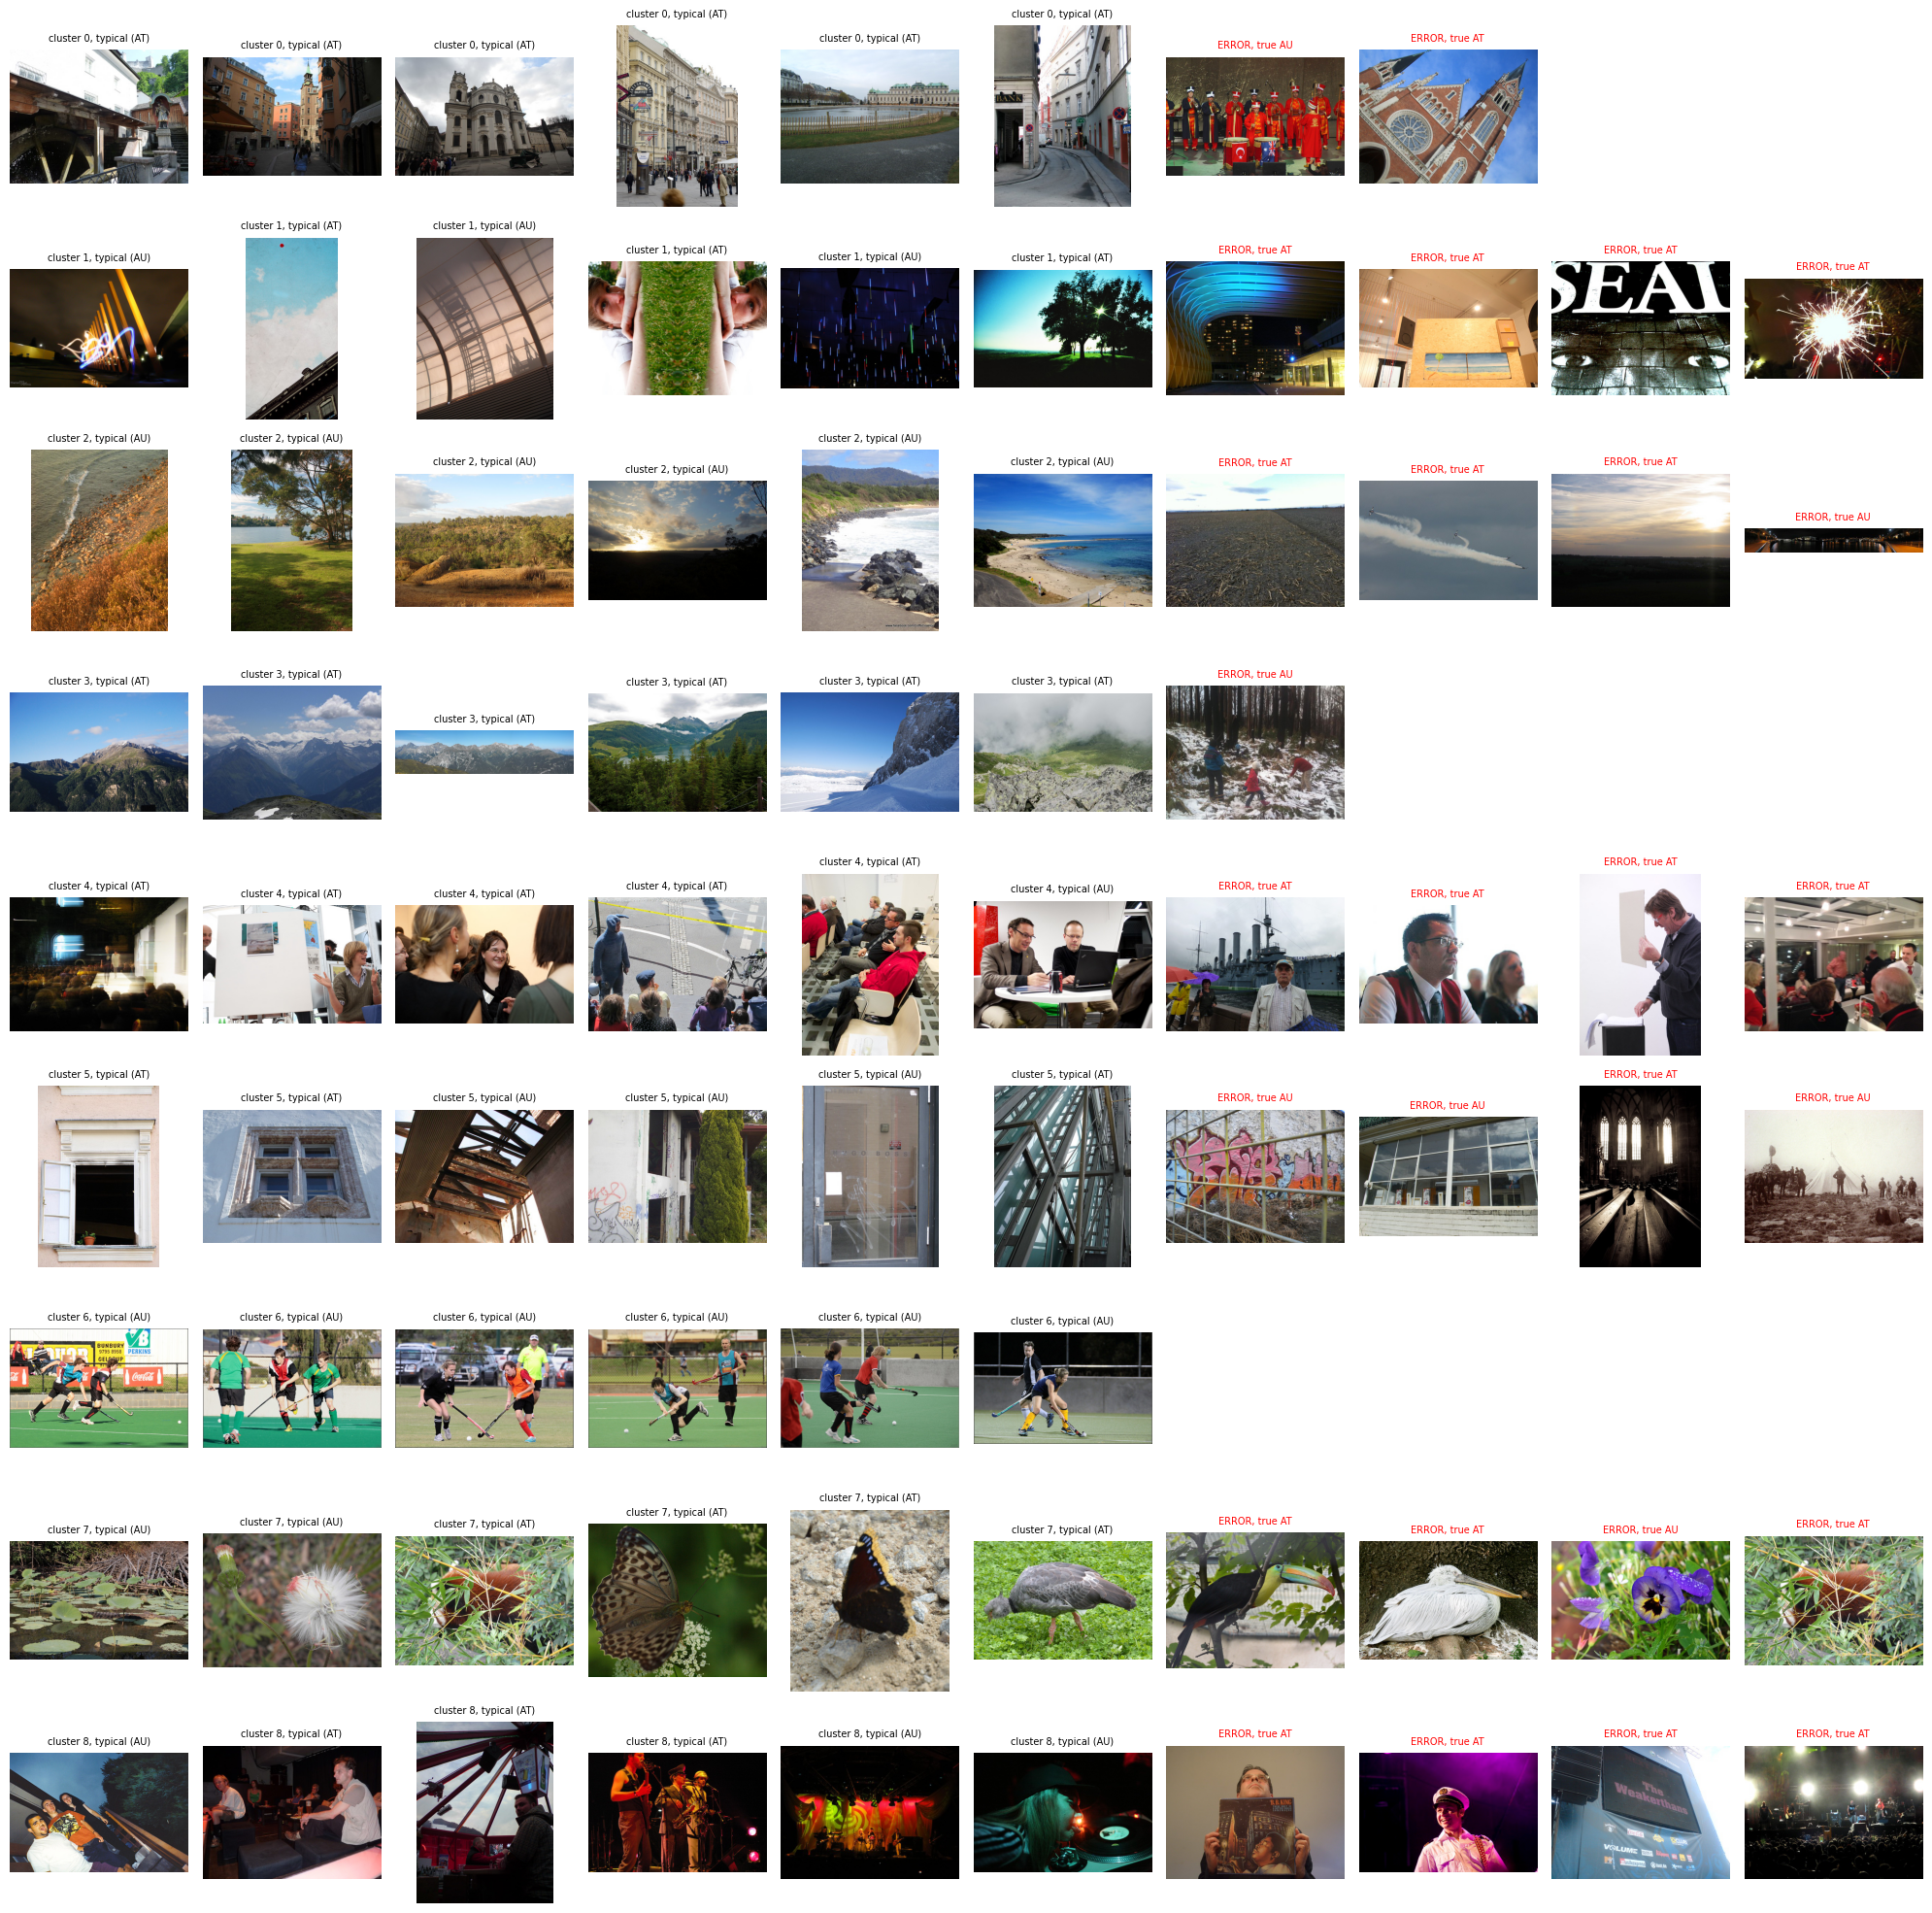

In [37]:
montage(ALL, df.cl.to_numpy())


## Margin vs local density


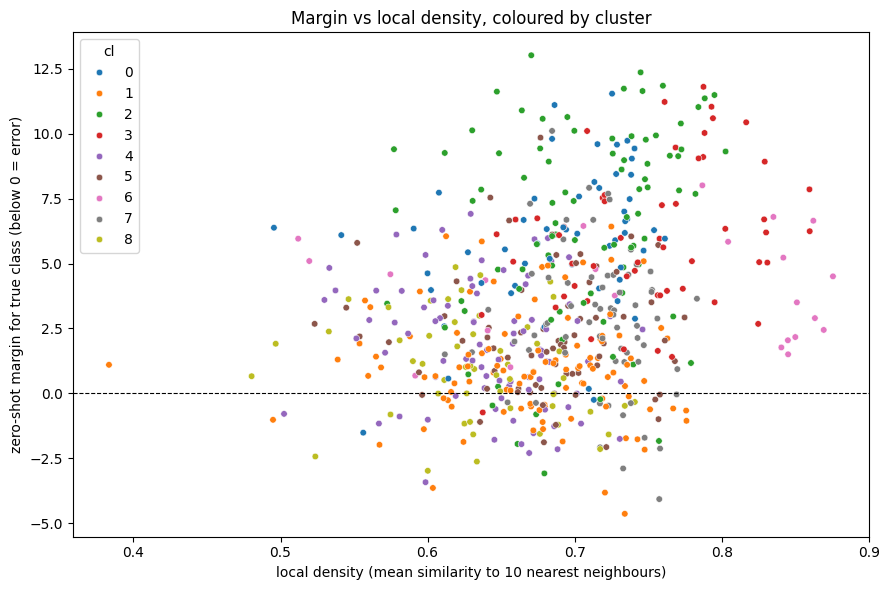

In [38]:
# Figure 2: are errors in sparse regions? Each point is an image.
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(x=df.dens, y=df.margin, hue=df.cl, palette="tab10", s=22, ax=ax)
ax.axhline(0, color="k", ls="--", lw=.8)
ax.set_xlabel("local density (mean similarity to 10 nearest neighbours)")
ax.set_ylabel("zero-shot margin for true class (below 0 = error)")
ax.set_title("Margin vs local density, coloured by cluster")
plt.tight_layout(); plt.show()


## Sub-clusters of the worst cluster


In [39]:
# Zoom into the cluster with the highest error rate and split it into sub-clusters.
worst = T1[T1.n >= 20].zs_err.idxmax()
ids = np.where(df.cl.to_numpy() == worst)[0]
km2, sil2 = best_kmeans(X[ids], range(2, 5))
sub = km2.labels_
print(f"Cluster {worst}: {len(ids)} images -> {km2.n_clusters} sub-clusters (silhouette {sil2:.2f})")


Cluster 8: 52 images -> 2 sub-clusters (silhouette 0.06)


In [40]:
display(summarize(ids, sub).style.format({"frac_AU": "{:.2f}", "zs_err": "{:.2f}", "knn_err": "{:.2f}",
                                          "prompt_flip": "{:.2f}", "density": "{:.3f}", "spread": "{:.3f}"}))


,n,frac_AU,zs_err,knn_err,prompt_flip,density,spread,scenes
cluster,,,,,,,,
0,26,0.54,0.19,0.50,0.50,0.621,0.672,"people 73%, animal 15%, food 4%"
1,26,0.35,0.50,0.31,0.27,0.645,0.662,"people 65%, forest 31%, sign with text 4%"


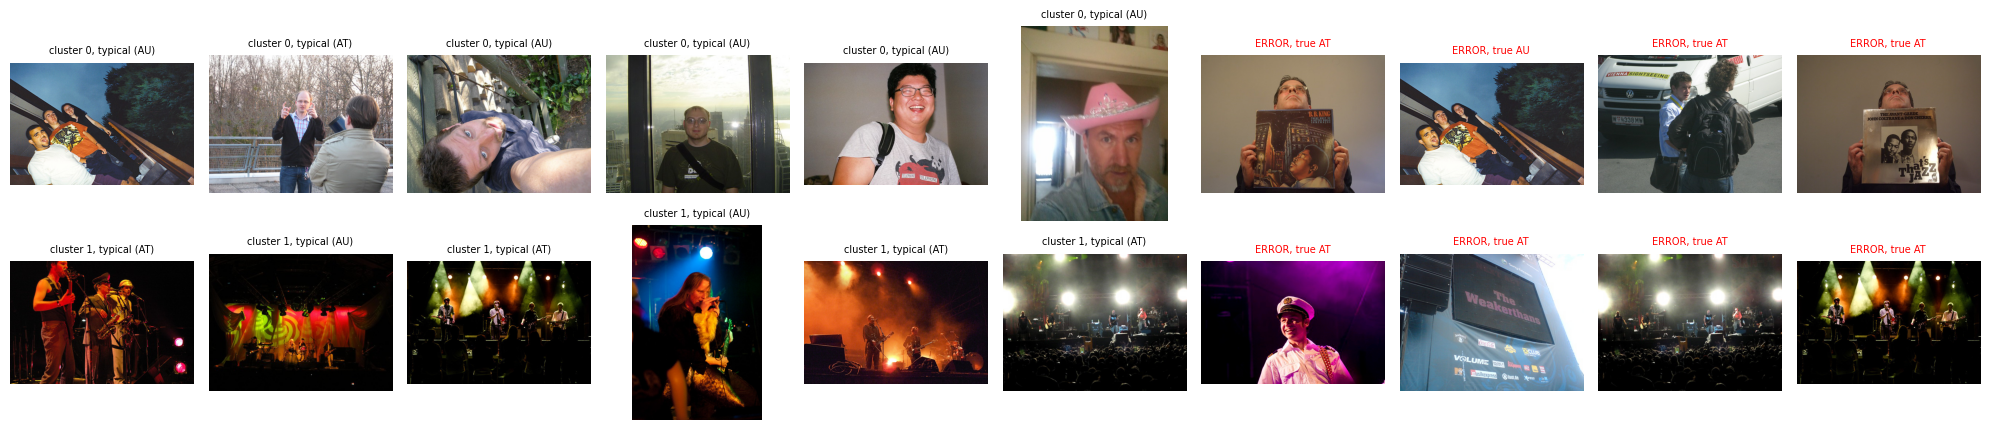

In [41]:
montage(ids, sub)


## Prediction-rate check


In [42]:
# Cluster-level prediction bias: pred_AU above frac_AU means the cluster leans toward Australia.
df["pred_AU"] = df["au_score"] > 0
chk = df.groupby("cl").agg(frac_AU=("country", lambda s: (s == "AU").mean()), pred_AU=("pred_AU", "mean"))
display(chk.round(2))
print(df[df.margin < 0].country.value_counts())


,frac_AU,pred_AU
cl,,
0,0.04,0.04
1,0.60,0.81
2,0.90,0.90
3,0.02,0.00
4,0.33,0.45
5,0.41,0.36
6,0.96,0.96
7,0.79,0.82
8,0.44,0.56


country
AT    69
AU    33
Name: count, dtype: int64


## Interpretation

Note: scene labels in the table come from CLIP text probes and are unreliable (e.g. "forest" in cluster 8 is green stage lighting). Clusters are described from the montage. The error images shown are each cluster's most confident errors.

**1. Where the errors are.** Clusters 0, 2, 3 and 6 (220 images) are each almost purely one country and have error rates of 7% or less. The montage shows why: Viennese streets and churches (0), Australian coast and bush (2), Alpine peaks and snow (3), field hockey matches (6). Clusters 1, 4, 5 and 8 (314 images, 52% of the data) hold about 80% of the errors. They are photos with little place information: abstract night and sky shots (1), conferences and social gatherings (4), windows, graffiti and glass facades (5), concerts and nightlife (8).

**2. Density and spread.** Error rate rises as clusters get sparser. Clusters 3 and 6 (density 0.75, spread 0.56-0.59) make 0-2% errors. Clusters 8 and 4 (density 0.633 and 0.641, spread about 0.70) make 35% and 24%. Cluster 6 is dense because it is one sport in one setting. Clusters 4 and 8 are sparse because they mix many unrelated event types. Figure 2 shows density does not decide a single image: errors occur from density 0.5 to 0.77.

**3. The model uses scene stereotypes, not place evidence.** The errors point in different directions depending on content:
- Snow and buildings pull toward Austria: in cluster 3 the one error is an Australian snowy forest, and in cluster 5 three of the four worst errors are Australian photos of graffiti, glass buildings and a sepia scene predicted as Austria.
- Nature, wildlife and night scenes pull toward Australia: in cluster 7 the worst errors are Austrian zoo animals (a toucan, a pelican), and in cluster 2 they are Austrian flat fields, a sunset and an airshow.
- Overall, 20 of the 27 errors shown are Austrian photos predicted as Australian.
Cluster 6's perfect score cannot separate recognition from this default: it contains one Austrian image, so there is no counter-example.

**4. Image-side or text-side.** In clusters 1, 4, 5 and 8 the nearest-neighbour error (0.28-0.39) is higher than the zero-shot error, so the image embedding alone barely separates the countries, and the text prompt recovers some signal. That signal is fragile: 35-46% of images in clusters 4, 5 and 8 change prediction when only the prompt wording changes.

**5. Inside cluster 8.** It splits into two sub-clusters. Sub-cluster 0 is snapshots and portraits of people: zero-shot error 19%, but its neighbours are at chance (50%) and half its images flip with prompt wording. Sub-cluster 1 is concert and stage photos: zero-shot error 50%, worse than predicting "Austria" for everything (35%), while neighbours do better (27%). All four worst errors there are Austrian concerts predicted as Australian. The image embedding holds country information that the text prompt fails to use, a text-side failure. A cluster that looks uniformly bad is two different problems.

**Conclusion.** CLIP separates Austria from Australia when the photo shows a place-specific scene. When it doesn't, CLIP does not guess at random. It falls back on scene stereotypes (snow and buildings mean Austria, wildlife and night scenes mean Australia), and the result is unstable under prompt changes.
